# Étape 2 — Pipelines de prétraitement et modélisation

**Projet — Prédiction du risque en santé mentale chez les étudiants universitaires**

Ce notebook construit une chaîne de traitement **complète et sans fuite de données** (data leakage) :

1. **Nettoyage léger** des données issues de l'EDA (correction de l'incohérence écran/réseaux, suppression de l'identifiant) ;
2. **Pipeline de prétraitement** avec `ColumnTransformer` : imputation, encodage et standardisation, chaque variable étant traitée selon sa nature ;
3. **Pipelines complets** pour 3 modèles : **Régression logistique**, **Random Forest** et **XGBoost** ;
4. **Optimisation des hyperparamètres** par `GridSearchCV` (validation croisée stratifiée 5 folds, métrique principale `f1_weighted`) ;
5. **Évaluation** sur un jeu de test tenu à l'écart : accuracy, balanced accuracy, precision/recall/F1 (weighted & macro), ROC-AUC (un-vs-rest), matrices de confusion ;
6. **Sauvegarde** des meilleurs modèles et du résumé des résultats.

> Principe clé : le prétraitement est **inclus dans le pipeline**. Il est donc appris **uniquement sur les données d'entraînement** de chaque fold de validation croisée — aucune information du jeu de test ne fuit vers l'apprentissage.


## 0. Imports et configuration

In [1]:
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
    label_binarize,
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

# Constantes du projet
DATA_PATH = "../data/student_mental_health.csv"
TARGET = "Mental_Health_Risk"
TARGET_NAMES = ["Low", "Medium", "High"]       # ordre des classes
TARGET_MAP = {"Low": 0, "Medium": 1, "High": 2}
RANDOM_STATE = 42


## 1. Chargement et nettoyage léger

In [2]:
# Chargement du jeu de données
df = pd.read_csv(DATA_PATH)

#    Corriger l'incohérence relevée dans l'EDA :
#    le temps d'écran total doit être >= au temps passé sur les réseaux sociaux
n_incoherent = int((df["Screen_Time_Hours"] < df["Social_Media_Hours"]).sum())
df["Screen_Time_Hours"] = np.maximum(df["Screen_Time_Hours"], df["Social_Media_Hours"])
print(f"Incohérences 'écran < réseaux sociaux' corrigées : {n_incoherent}")

#    Supprimer l'identifiant : aucune information prédictive
df = df.drop(columns=["Student_ID"])
df.head()

Incohérences 'écran < réseaux sociaux' corrigées : 37


,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


## 2. Variables explicatives, cible et découpage train/test

In [3]:
# Séparation variables explicatives / cible
X = df.drop(columns=[TARGET])
y = df[TARGET].map(TARGET_MAP)  # Low=0, Medium=1, High=2

print("Répartition des classes (encodées) :")
print(y.value_counts().sort_index().rename(index={v: k for k, v in TARGET_MAP.items()}))

# Découpage stratifié : 80 % entraînement / 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"\nTrain : {X_train.shape[0]} lignes | Test : {X_test.shape[0]} lignes")
print("Proportions y_train :", (y_train.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
print("Proportions y_test  :", (y_test.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())


Répartition des classes (encodées) :
Mental_Health_Risk
Low       660
Medium    660
High      680
Name: count, dtype: int64

Train : 1600 lignes | Test : 400 lignes
Proportions y_train : {0: 33.0, 1: 33.0, 2: 34.0}
Proportions y_test  : {0: 33.0, 1: 33.0, 2: 34.0}


## 3. Pipeline de prétraitement avec `ColumnTransformer`

In [4]:
# ── Groupes de variables selon leur nature ──────────────────────────────
numeric_features = [
    "Age", "Year_of_Study", "Sleep_Hours", "Study_Hours_Per_Week", "GPA",
    "Social_Media_Hours", "Screen_Time_Hours", "Financial_Stress",
    "Family_Support", "Attendance_Rate",
]
ordinal_features = ["Physical_Activity", "Diet_Quality"]
ordinal_categories = [["Low", "Moderate", "High"], ["Poor", "Average", "Good"]]
binary_features = ["Part_Time_Job", "Previous_Mental_Health_History"]
binary_categories = [["No", "Yes"], ["No", "Yes"]]
nominal_features = ["Gender"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

ordinal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    )),
])

binary_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=binary_categories,
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    )),
])

nominal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# ── Assemblage final ────────────────────────────────────────────────────
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("ord", ordinal_transformer, ordinal_features),
        ("bin", binary_transformer, binary_features),
        ("nom", nominal_transformer, nominal_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer

## 4. Pipelines complets pour les 3 modèles

In [5]:
# Un pipeline complet = prétraitement + classifieur
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    ]),
    "XGBoost": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            random_state=RANDOM_STATE,
            eval_metric="mlogloss",
            tree_method="hist",
            n_jobs=1,
        )),
    ]),
}


## 5. Réglage des hyperparamètres avec `GridSearchCV`

In [6]:
# Grilles d'hyperparamètres à explorer pour chaque modèle
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10],          # inverse de la régularisation
    },
    "Random Forest": {
        "classifier__n_estimators": [200, 400],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_split": [2, 5],
    },
    "XGBoost": {
        "classifier__n_estimators": [200, 400],
        "classifier__max_depth": [3, 5],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__subsample": [0.8, 1.0],
    },
}

for name, grid in param_grids.items():
    n = int(np.prod([len(v) for v in grid.values()]))
    print(f"{name:20s}: {n:2d} combinaisons * 5 folds = {n * 5} entraînements")

Logistic Regression :  4 combinaisons * 5 folds = 20 entraînements
Random Forest       : 12 combinaisons * 5 folds = 60 entraînements
XGBoost             : 16 combinaisons * 5 folds = 80 entraînements


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

searches = {}
for name, pipeline in models.items():
    print(f"GridSearchCV — {name} ...")
    t0 = time.perf_counter()

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="f1_weighted",   
        cv=cv,
        n_jobs=-1,               
        error_score="raise",
    )
    search.fit(X_train, y_train)

    elapsed = time.perf_counter() - t0
    searches[name] = search
    print(f"   ✔ terminé en {elapsed:.1f}s | meilleur F1 (CV) = {search.best_score_:.4f}")
    print(f"   meilleurs paramètres : {search.best_params_}")

GridSearchCV — Logistic Regression ...
   ✔ terminé en 3.5s | meilleur F1 (CV) = 0.7591
   meilleurs paramètres : {'classifier__C': 10}
GridSearchCV — Random Forest ...
   ✔ terminé en 8.7s | meilleur F1 (CV) = 0.6959
   meilleurs paramètres : {'classifier__max_depth': 10, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}
GridSearchCV — XGBoost ...
   ✔ terminé en 6.1s | meilleur F1 (CV) = 0.7171
   meilleurs paramètres : {'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 400, 'classifier__subsample': 0.8}


## 6. Évaluation sur le jeu de test

### 6.1 Métriques de performance

In [8]:
def evaluate(search, X_test, y_test):
    """Évalue un modèle optimisé et retourne les métriques, prédictions et probabilités."""
    best = search.best_estimator_
    y_pred = best.predict(X_test)
    y_proba = best.predict_proba(X_test)

    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1 (weighted)": f1_score(y_test, y_pred, average="weighted"),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
        "ROC-AUC (OVR)": roc_auc_score(y_test, y_proba, multi_class="ovr", average="weighted"),
    }
    return metrics, y_pred, y_proba


results = {}
for name, search in searches.items():
    metrics, y_pred, y_proba = evaluate(search, X_test, y_test)
    results[name] = {"metrics": metrics, "y_pred": y_pred, "y_proba": y_proba}

    print(f"══ {name} ══")
    for metric_name, value in metrics.items():
        print(f"   {metric_name:22s}: {value:.4f}")
    print()
    print(classification_report(y_test, y_pred, target_names=TARGET_NAMES, digits=3))

══ Logistic Regression ══
   Accuracy              : 0.7675
   Balanced accuracy     : 0.7667
   Precision (weighted)  : 0.7703
   Recall (weighted)     : 0.7675
   F1 (weighted)         : 0.7685
   F1 (macro)            : 0.7678
   ROC-AUC (OVR)         : 0.9182

              precision    recall  f1-score   support

         Low      0.831     0.780     0.805       132
      Medium      0.645     0.674     0.659       132
        High      0.833     0.846     0.839       136

    accuracy                          0.767       400
   macro avg      0.770     0.767     0.768       400
weighted avg      0.770     0.767     0.769       400

══ Random Forest ══
   Accuracy              : 0.6825
   Balanced accuracy     : 0.6814
   Precision (weighted)  : 0.6811
   Recall (weighted)     : 0.6825
   F1 (weighted)         : 0.6818
   F1 (macro)            : 0.6807
   ROC-AUC (OVR)         : 0.8689

              precision    recall  f1-score   support

         Low      0.719     0.735     0.

### 6.2 Matrices de confusion

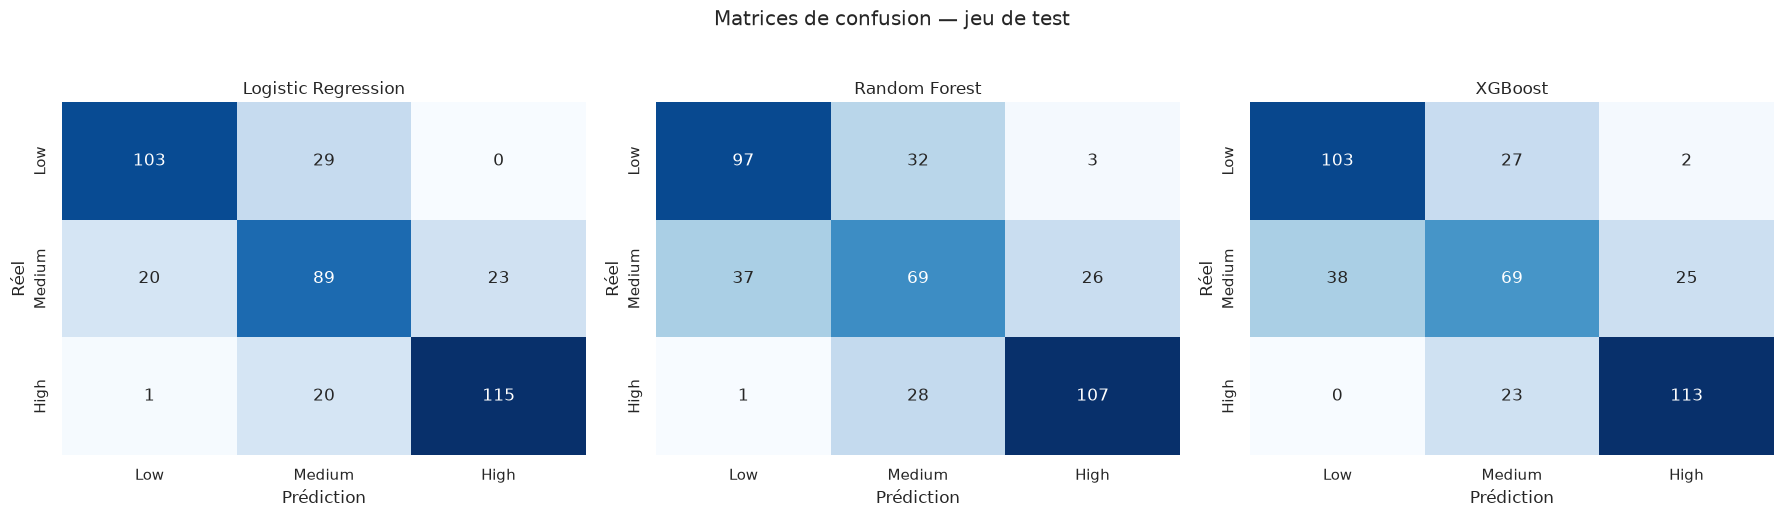

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, res["y_pred"], labels=[0, 1, 2])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=TARGET_NAMES, yticklabels=TARGET_NAMES, ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Réel")
plt.suptitle("Matrices de confusion — jeu de test", y=1.03)
plt.tight_layout()
plt.show()

### 6.3 Comparaison des modèles

In [10]:
# Tableau comparatif trié par la métrique principale
metrics_df = (
    pd.DataFrame({name: res["metrics"] for name, res in results.items()})
    .T
    .sort_values("F1 (weighted)", ascending=False)
    .round(4)
)
metrics_df

,Accuracy,Balanced accuracy,Precision (weighted),Recall (weighted),F1 (weighted),F1 (macro),ROC-AUC (OVR)
Logistic Regression,0.7675,0.7667,0.7703,0.7675,0.7685,0.7678,0.9182
XGBoost,0.7125,0.7113,0.7068,0.7125,0.7089,0.7077,0.8867
Random Forest,0.6825,0.6814,0.6811,0.6825,0.6818,0.6807,0.8689


### 6.4 Courbes ROC (micro-average, un-vs-rest)

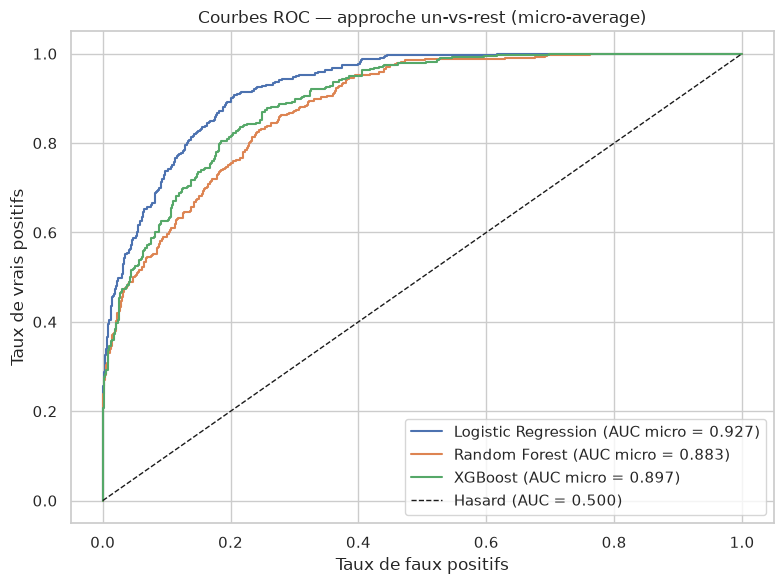

In [11]:
# Courbes ROC micro-average : une courbe par modèle
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

fig, ax = plt.subplots(figsize=(8, 6))
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), res["y_proba"].ravel())
    auc_micro = roc_auc_score(y_test_bin, res["y_proba"], average="micro", multi_class="ovr")
    ax.plot(fpr, tpr, label=f"{name} (AUC micro = {auc_micro:.3f})")

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Hasard (AUC = 0.500)")
ax.set_xlabel("Taux de faux positifs")
ax.set_ylabel("Taux de vrais positifs")
ax.set_title("Courbes ROC — approche un-vs-rest (micro-average)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Lecture des courbes ROC :**

| Modèle | AUC micro |
|---|---|
| Logistic Regression | 0.927 |
| XGBoost | 0.897 |
| Random Forest | 0.883 |

Toutes les courbes sont **nettement au-dessus de la diagonale du hasard** (AUC = 0,500), ce qui confirme la qualité de la discrimination. **Logistic Regression** obtient la meilleure AUC micro (0.927). Les écarts entre modèles restent faibles : même le moins bon modèle classe correctement les étudiants dans la très grande majorité des cas, ce qui traduit la **richesse du signal** contenu dans les variables comportementales et académiques.

In [12]:
# importances = searches['Random Forest'].named_steps['classifier'].feature_importances_

# features = searches['Random Forest'].named_steps['preprocessor'].get_feature_names_out()

# importance_df = pd.DataFrame({
#     'Feature': features,
#     'Importance': importances
# })

# importance_df = importance_df.sort_values(
#     by='Importance',
#     ascending=False
# )

# print(importance_df)

# importance_df.plot(
#     x='Feature',
#     y='Importance',
#     kind='barh'
# )

# plt.show()